# GRADIENTE DESCENDENTE

**Por**: Daniela Andrea Torres Gómez


**PARTE 2:** 
Encuentre el valor mínimo de la función del numeral 3 – Parte 1 utilizando el algoritmo de gradiente descendente.

$𝑓(𝑥,𝑦) = (𝑥^2+𝑦−11)^2+(𝑥+𝑦^2−7)^2$ para $𝑥,𝑦 ∈ [−5,5]$

In [1]:
import numpy as np 
import matplotlib.pyplot as plt

In [7]:
f = lambda x,y: (x**2 + y - 11)**2 + (x + y**2 - 7)**2

In [9]:
def plot(funcion, xy_lim, step):
    y = np.arange(xy_lim[0], xy_lim[1], step)
    x = np.arange(xy_lim[0], xy_lim[1], step)
    X, Y = np.meshgrid(x, y)
    Z = funcion(X, Y)
    print('Z shape:' ,Z.shape)
    
    # crear una imagen en 3D
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='jet')
    plt.show()

Z shape: (100, 100)


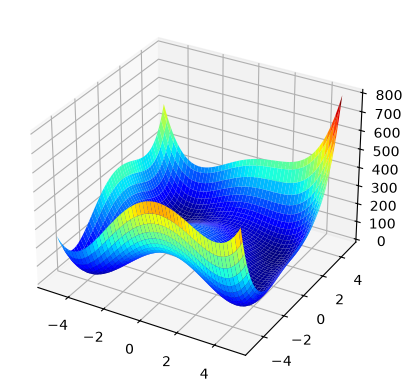

In [12]:
plot(f, xy_lim=(-5, 5), step=0.1)

### Derivadas:


$
\begin{equation}
\nabla f(x,y)  = 
\begin{bmatrix}
\frac{\partial f(x,y)}{\partial x} \\
\frac{\partial f(x,y)}{\partial y} 
\end{bmatrix}
\end{equation}
$

$ 
\begin{equation}
\frac{\partial f(x,y)}{\partial x}  = 4 x (𝑥^2+𝑦−11)  +  2 (𝑥+𝑦^2−7) 
\end{equation}
$ 

$ 
\begin{equation}
\frac{\partial f(x,y)}{\partial y}  = 2 (𝑥^2+𝑦−11)  +  4 y (𝑥+𝑦^2−7)
\end{equation}
$ 


In [5]:
dfdx = lambda x,y: 2*(x**2 + y - 11)*2*x + 2*(x + y**2 - 7)
dfdy = lambda x,y: 2*(x**2 + y - 11) + 2*(x + y**2 - 7)*2*y

## Gradiente descendiente

$
X_{t+1} = X_t - \alpha \nabla f(X)
$

In [77]:
def gradiente_descendente(f,x0, y0 ,dfdx, dfdy, bounds, alpha=0.01, n_iter=100):
    
    x = x0
    y = y0
    
    X = np.array([[x, y]])
    Z = np.array([[f(x, y)]])
    
    for i in range(n_iter):
        x = x - alpha * dfdx(x, y)
        y = y - alpha * dfdy(x, y)
        
        solution = np.array([[x, y]])
        evaluation = np.array([[f(x, y)]])
        
        X = np.concatenate((X, solution))
        Z = np.concatenate((Z, evaluation))
        print(f"Iteración {i+1}: X = {solution}, f(x, y) = {f(x, y)}")
        
    #Grafica
    x1= np.arange(bounds[0], bounds[1], 0.05)
    y1= np.arange(bounds[0], bounds[1], 0.05)
    X1, Y1 = np.meshgrid(x1, y1)

    plt.contourf(x1, y1, f(X1, Y1), levels=50, cmap='jet')
    plt.scatter(X[:,0], X[:,1], c='black', marker='.')
    plt.scatter(X[X.shape[0]-1][0], X[X.shape[0]-1][1], c='red', marker='.')
    plt.colorbar()
    plt.show()
    
    return X, Z

Iteración 1: X = [[0.14     0.219608]], f(x, y) = 162.19488669310098
Iteración 2: X = [[0.33649588 0.49106196]], f(x, y) = 149.31749376744705
Iteración 3: X = [[0.60486765 0.81480304]], f(x, y) = 129.2662608812362
Iteración 4: X = [[0.95706807 1.17550133]], f(x, y) = 101.08783682248878
Iteración 5: X = [[1.39133302 1.5320225 ]], f(x, y) = 67.37144881890865
Iteración 6: X = [[1.87575477 1.82119932]], f(x, y) = 35.30647983953543
Iteración 7: X = [[2.33660108 1.99368065]], f(x, y) = 13.052696121848069
Iteración 8: X = [[2.68185476 2.05734396]], f(x, y) = 3.070895889950852
Iteración 9: X = [[2.87132759 2.06274876]], f(x, y) = 0.49581523738598055
Iteración 10: X = [[2.94836448 2.05086271]], f(x, y) = 0.08952167310023991
Iteración 11: X = [[2.9755012  2.03788084]], f(x, y) = 0.028276651057108172
Iteración 12: X = [[2.98584709 2.02750281]], f(x, y) = 0.01260789117047011
Iteración 13: X = [[2.99074813 2.01982833]], f(x, y) = 0.006231019687979567
Iteración 14: X = [[2.99359754 2.01427678]], f(x

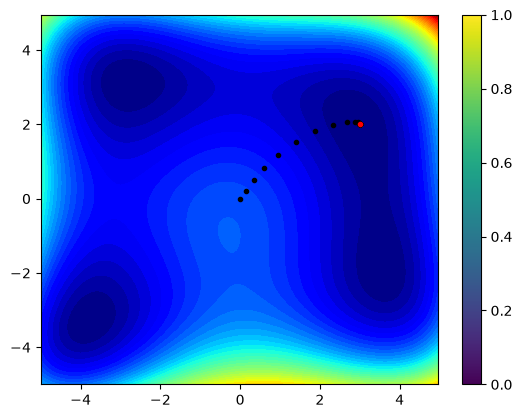

In [78]:
X, Z =  gradiente_descendente(f, 0, 0, dfdx, dfdy, bounds=(-5, 5), alpha=0.01)